In [118]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [119]:
import sys
sys.path.append("../src")

In [120]:
DATA_DIR = "../data/troupe/TLS"

In [121]:
import pickle

with open(f"{DATA_DIR}/processed_data/trees.pkl", "rb") as f:
    data = pickle.load(f)

# print(type(data))
print('Number of trees: ', len(data))

Number of trees:  12


In [122]:
t_id = 2
t = data[t_id]
t.describe()
# t.convert_to_ultrametric()
# t.describe()

# t.show()
# t.write(outfile='test.nwk')

Number of leaf nodes:	205
Total number of nodes:	409
Rooted:	Yes
Most distant node:	CTCTCAGGTGAGTGAC-1
Max. distance:	0.993519


In [123]:
import networkx as nx

def ete_to_nx(t):
    G = nx.DiGraph()

    node_ids = {}
    
    for i, node in enumerate(t.traverse("preorder")):
        node_ids[node] = i

    for node in t.traverse("preorder"):
        node_id = node_ids[node]

        attrs = {
            "name": node.name,
            "dist": node.dist,
            "is_leaf": node.is_leaf()
        }

        for attr in ["state", "state_coarse", "state_fine"]:
            if hasattr(node, attr):
                attrs[attr] = getattr(node, attr)

        G.add_node(node_id, **attrs)

        if node.up:
            G.add_edge(node_ids[node.up], node_id, weight=node.dist)

    G.graph["root"] = node_ids[t]

    return G

In [124]:
T = ete_to_nx(t)
T

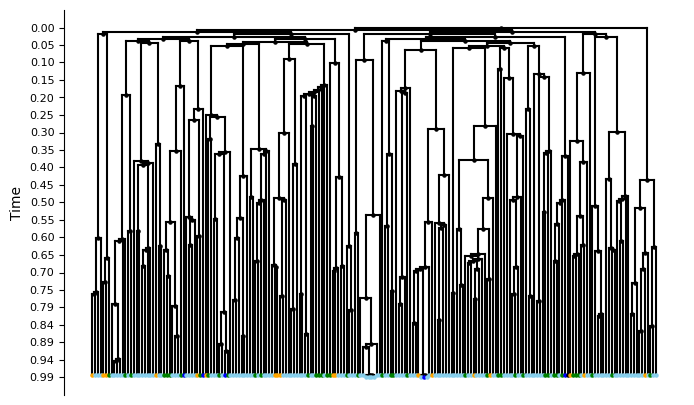

In [125]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [126]:
leaves = [n for n, d in T.out_degree() if d == 0]

In [127]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')

In [128]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9870389566041347 0.9935194794114179


In [129]:
EPS = 1e-4
scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1

In [130]:
for u, v, d in T.edges(data=True):
    d['weight'] *= scale

In [131]:
for leaf in leaves:
    dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
    
    if dist > 1.0:
        parent = list(T.predecessors(leaf))[0]
        
        edge_length = T[parent][leaf]['weight']
        
        excess = dist - 1.0
        T[parent][leaf]['weight'] = max(edge_length - excess, 0)  # avoid negative lengths

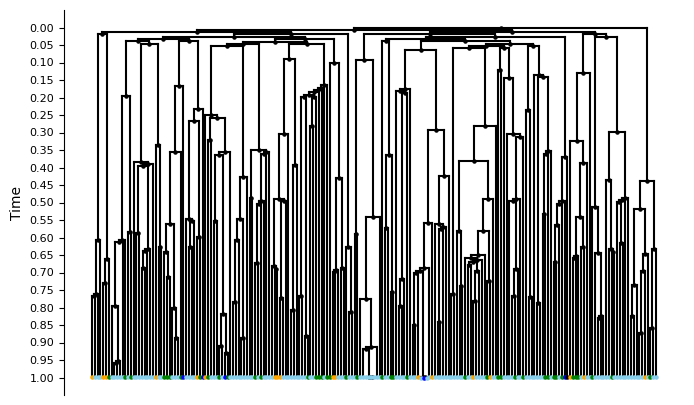

In [132]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [133]:
# If edges have weight attribute 'length' or similar
distances = {}
for leaf in leaves:
    distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')

In [134]:
min_dist = min(distances.values())
max_dist = max(distances.values())
print(min_dist, max_dist)

0.9999 1.0


In [135]:
from collections import defaultdict

cell_state_counts = defaultdict(int)

for node, d in T.nodes(data=True):
    if 'state' in d:
        cell_state_counts[d.get('state')] += 1

cell_state_counts

defaultdict(int,
            {'NMPs': 18,
             'NeuralTube': 139,
             'Somite': 42,
             'Endothelial': 5,
             'PCGLC': 1})

## Differentiation Map from CARTA

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:206: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


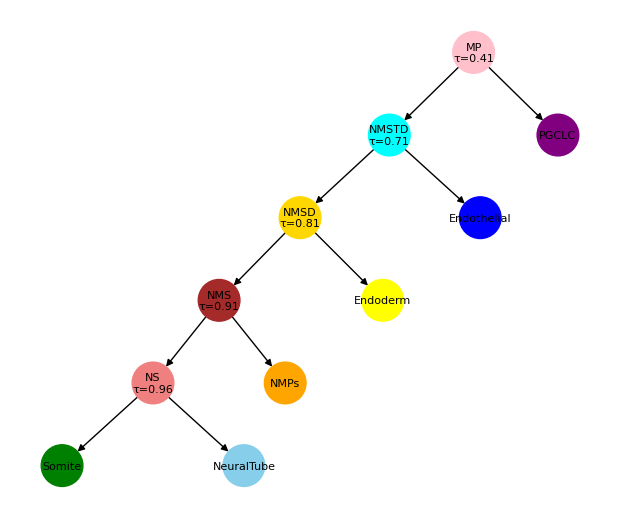

In [136]:
import string
from plotters import plot_differentiation_tree

diff_map_edges = [
    ("MP", "PGCLC"),
    ("MP", "NMSTD"),
    ("NMSTD", "NMSD"),
    ("NMSTD", "Endothelial"),
    ("NMSD", "NMS"),
    ("NMSD", "Endoderm"),
    ("NMS", "NS"),
    ("NMS", "NMPs"),
    ("NS", "Somite"),
    ("NS", "NeuralTube"),
]

a = 0.96
b = 0.05
c = 0.1
d = 0.1
e = 0.3

diff_times = {
    "MP":  a- b - c - d - e,
    "NMSTD": a - b - c - d,
    "NMSD": a - b - c,
    "NMS": a - b,
    "NS": a,
    "PGCLC": None,
    "Endothelial": None,
    "Endoderm": None,
    "NMPs": None,
    "Somite": None,
    "NeuralTube": None
}

diff_T = nx.DiGraph()


for k, v in diff_times.items():
    diff_T.add_node(k, diff_time=v)

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

plot_differentiation_tree(diff_T)

In [137]:
from likelihood import add_node_times
T = add_node_times(T, root=T.graph['root'])

In [138]:
rev_diff_T = diff_T.copy()
for n in diff_T.nodes():
    if diff_T.nodes[n]['diff_time'] is None: rev_diff_T.nodes[n]['diff_time'] = 0
    else: rev_diff_T.nodes[n]['diff_time'] = 1 - diff_T.nodes[n]['diff_time']

In [139]:
from likelihood import assign_states_to_internal_nodes

T = assign_states_to_internal_nodes(T, rev_diff_T, correct=True)

Children have > 1 types ['NeuralTube', 'Endothelial'] at 9.999835097185272e-05
Setting state for descendant 248 at 0.0 to ?
Setting state for descendant 249 at 0.0 to ?
Children have > 1 types ['NS', 'Endothelial'] at 0.0710521333042049
Setting state for descendant 105 at 9.999960016737752e-05 to ?
Setting state for descendant 106 at 9.999960016737752e-05 to ?
Children have > 1 types ['MP', 'PCGLC'] at 0.6308254049161346
Setting state for descendant 337 at 0.5032020699641963 to ?
Setting state for descendant 338 at 0.496637108380537 to ?
Setting state for descendant 339 at 0.43500912003669145 to ?
Setting state for descendant 340 at 0.32891719231362815 to ?
Setting state for descendant 341 at 9.999922405756756e-05 to ?
Setting state for descendant 342 at 9.999922405756756e-05 to ?
Setting state for descendant 343 at 9.999922405756756e-05 to ?
Setting state for descendant 344 at 9.999922405756756e-05 to ?
Setting state for descendant 345 at 9.999914433300727e-05 to ?
Setting state for d

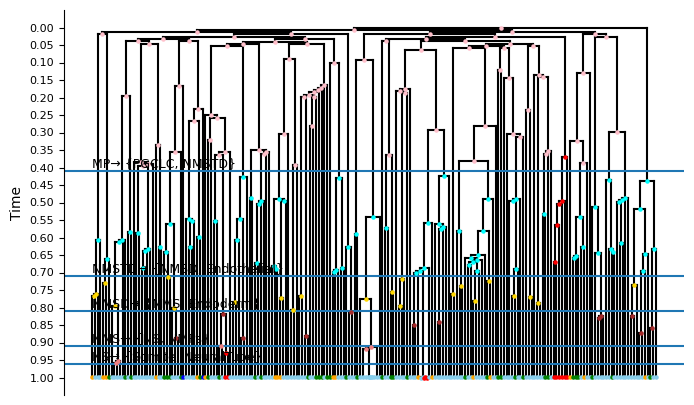

In [140]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_T=diff_T)

In [141]:
types = list(diff_T.nodes())

transition_maps = [
    (i, succ)
    for i in diff_T.nodes()
    if (succ := list(diff_T.successors(i)))
]

print(types)
print(transition_maps)

['MP', 'NMSTD', 'NMSD', 'NMS', 'NS', 'PGCLC', 'Endothelial', 'Endoderm', 'NMPs', 'Somite', 'NeuralTube']
[('MP', ['PGCLC', 'NMSTD']), ('NMSTD', ['NMSD', 'Endothelial']), ('NMSD', ['NMS', 'Endoderm']), ('NMS', ['NS', 'NMPs']), ('NS', ['Somite', 'NeuralTube'])]


### Considering all trees together

In [142]:
len(data)

12

In [149]:
Ts = []

for t in data[:3]:
    T = ete_to_nx(t)
    Ts.append(T)

In [150]:
## scale edges
EPS = 1e-4

for T in Ts:
    leaves = [n for n, d in T.out_degree() if d == 0]
    # If edges have weight attribute 'length' or similar
    distances = {}
    for leaf in leaves:
        distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
    scale = (1 - EPS) / min_dist  # scale to make the min leaf at 1
    for u, v, d in T.edges(data=True):
        d['weight'] *= scale
    
    for leaf in leaves:
        dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='weight')
        
        if dist > 1.0:
            parent = list(T.predecessors(leaf))[0]
            
            edge_length = T[parent][leaf]['weight']
            
            excess = dist - 1.0
            T[parent][leaf]['weight'] = max(edge_length - excess, 0)  # avoid negative lengths
        

In [151]:
## add node times and assign internal states
for i, T in enumerate(Ts):
    print('='*50)
    print('Processing tree', i)
    print('='*50)
    T = add_node_times(T, root=T.graph['root'])
    T = assign_states_to_internal_nodes(T, rev_diff_T, correct=True)

Processing tree 0
Children have > 1 types ['Somite', 'NMPs'] at 0.015065184919464403
Setting state for descendant 276 at 0.007532592399324911 to ?
Setting state for descendant 277 at 0.007532592399324911 to ?
Children have > 1 types ['Somite', 'NMPs'] at 0.015065185015963434
Setting state for descendant 208 at 0.007532592495823942 to ?
Setting state for descendant 209 at 0.007532592495823942 to ?
Children have > 1 types ['NeuralTube', 'Somite'] at 0.015065185348234977
Setting state for descendant 161 at 0.007532592828095486 to ?
Setting state for descendant 162 at 0.007532592828095486 to ?
Children have > 1 types ['Endothelial', 'NMPs'] at 0.015065185435983008
Setting state for descendant 401 at 0.007532592915843517 to ?
Setting state for descendant 402 at 0.007532592915843517 to ?
Children have > 1 types ['NeuralTube', 'Somite'] at 0.015065186133222608
Setting state for descendant 14 at 0.007532593613083116 to ?
Setting state for descendant 15 at 0.007532593613083116 to ?
Children hav

Drawing tree 0


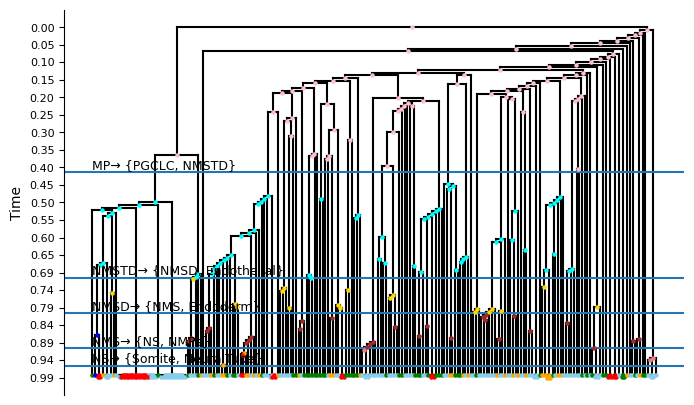

Drawing tree 1


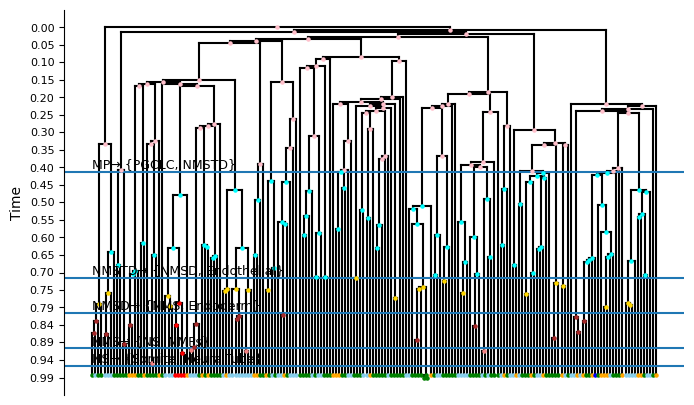

Drawing tree 2


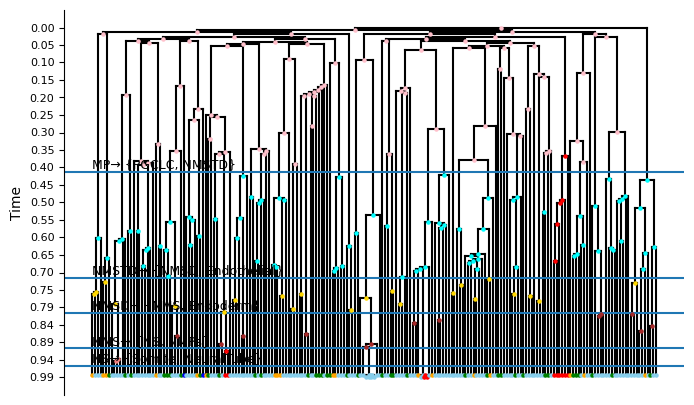

In [152]:
## draw trees
for i, T in enumerate(Ts):
    print('='*50)
    print('Drawing tree', i)
    print('='*50)
    draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False, diff_T=diff_T)

In [153]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit as sigmoid

from likelihood import calculate_log_likelihood_graph_diff_opt


MAX_DEATH = 1.0
MAX_BIRTH = 10.0


def unpack_params(theta):

    k = 0

    # -------------------------
    # Death rates: (0, 1)
    # -------------------------
    death = {}
    for t in types:
        death[t] = MAX_DEATH * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Birth rates: (death, 10)
    # -------------------------
    birth = {}
    for t in types:
        birth[t] = death[t] + (MAX_BIRTH - death[t]) * sigmoid(theta[k])
        k += 1

    # -------------------------
    # Transition matrix
    # -------------------------
    Q = pd.DataFrame(0.0, index=types, columns=types)

    for i, transition_to in transition_maps:

        logits = []
        js = []

        for j in transition_to:
            logits.append(theta[k])
            js.append(j)
            k += 1

        logits = np.array(logits)
        logits -= np.max(logits)

        exp_logits = np.exp(logits)
        probs = exp_logits / exp_logits.sum()

        for idx, j in enumerate(js):
            Q.loc[i, j] = probs[idx]

    return birth, death, Q


def neg_log_likelihood(theta, trees, diff_T, sampling_rate=1.0):

    birth, death, Q = unpack_params(theta)

    total_nll = 0.0

    for cell_lineage_T in trees:

        # try:
        l = calculate_log_likelihood_graph_diff_opt(
            T=cell_lineage_T,
            birth_rates=birth,
            death_rates=death,
            sampling_rate=sampling_rate,
            transition_probabilities=Q,
            diff_T=diff_T
        )
        
        total_nll += -l

    return total_nll


def pack_initial():

    params = []

    # death parameters
    for t in types:
        params.append(0.0)

    # birth parameters
    for t in types:
        params.append(0.0)

    # transition logits
    for i, transition_to in transition_maps:
        for j in transition_to:
            params.append(0.0)

    return np.array(params)


def find_params(trees, diff_T):

    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(trees, diff_T, 0.5),
        method="L-BFGS-B"
    )

    print(result)

    birth, death, Q = unpack_params(result.x)

    return birth, death, Q

In [154]:
birth_rates, death_rates, Q = find_params(Ts, rev_diff_T)
birth_rates, death_rates, Q

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 180.5827065631758
        x: [-5.714e+00  5.553e+00 ... -2.385e-01  7.285e-01]
      nit: 50
      jac: [ 6.986e-03 -8.274e-03 ...  1.472e-01  1.124e-01]
     nfev: 2475
     njev: 75
 hess_inv: <32x32 LbfgsInvHessProduct with dtype=float64>


({'MP': np.float64(5.2970511356845975),
  'NMSTD': np.float64(3.8416921003826237),
  'NMSD': np.float64(2.6171270808184293),
  'NMS': np.float64(1.3717271950255034),
  'NS': np.float64(0.5197517304614305),
  'PGCLC': np.float64(2.0369220565737423),
  'Endothelial': np.float64(3.212259617056974),
  'Endoderm': np.float64(2.152628904275394),
  'NMPs': np.float64(0.05655517025368579),
  'Somite': np.float64(0.11013000727525023),
  'NeuralTube': np.float64(9.98873609714053)},
 {'MP': np.float64(0.0032880803389897574),
  'NMSTD': np.float64(0.9961406728633134),
  'NMSD': np.float64(0.7315543068777822),
  'NMS': np.float64(0.917198571390679),
  'NS': np.float64(0.5197423362069098),
  'PGCLC': np.float64(0.6373008309915413),
  'Endothelial': np.float64(0.7955714040783496),
  'Endoderm': np.float64(0.5759748598103762),
  'NMPs': np.float64(0.056368412520530445),
  'Somite': np.float64(0.11006118634020907),
  'NeuralTube': np.float64(0.9953927943908429)},
               MP  NMSTD     NMSD  NMS 

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:206: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


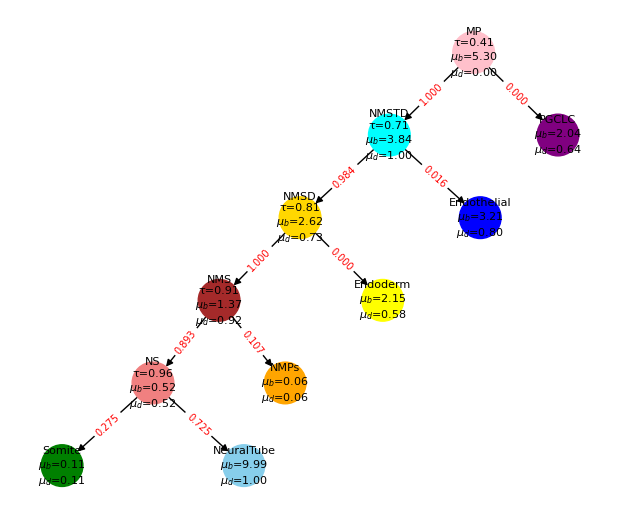

In [155]:
plot_differentiation_tree(diff_T, birth_rates, death_rates, transition_probabilities=Q)